# Cálculo de VaR y CVaR
---
Nombre: **Alan Jesús Hernández Soto**  
Carrera: **Ingeniería Financiera**  
Materia: **Simulación de Procesos Financieros**  
Tipo de trabajo: **Actividad**

---

## Importación de librerías
Se cargan las herramientas para descargar datos, realizar cálculos numéricos y graficar los resultados.

In [86]:
import yfinance as yf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

## 1. Descarga y simulación de datos multiactivo
Se descargan precios ajustados de AAPL, MSFT y NVDA y se calculan sus rendimientos logarítmicos. Con la matriz de covarianza anualizada y la descomposición de Cholesky se generan 10,000 escenarios correlacionados de precios para un horizonte de un año.

In [87]:
ticker = ['AAPL', 'MSFT', 'NVDA']
prices = yf.download(ticker, start='2025-11-04', end = '2026-11-04', auto_adjust=True)['Close']
rets = np.log(prices / prices.shift(1)).dropna()

M = 10000
n_act = len(ticker)
cov  = rets.cov()*252

L = np.linalg.cholesky(cov)
# corr = rets.corr()
# L = np.linalg.cholesky(corr)
E = np.random.normal(0,1, size=(n_act, M))
Z = L @ E
Z = Z.T

T = 1

np.random.seed(67)
ST = np.zeros(shape=(M, n_act))
cont = 0
for ticker in prices.columns:
    S0 = prices[ticker].iloc[-1]
    mu_r = rets[ticker].mean()*252
    print(ticker, mu_r)
    #vol = rets[ticker].std()*np.sqrt(252)
    vol = cov.loc[ticker, ticker]
    print(ticker, vol)
    #st = S0*np.exp((mu_r-0.5*vol**2)*T + np.sqrt(T)*Z[:, cont])
    st = S0 * np.exp((mu_r-0.5*vol**2)* T + np.sqrt(T) * Z[:, cont])
    ST[:, cont] = st
    cont += 1


[*********************100%***********************]  3 of 3 completed

AAPL 0.2116302937743865
AAPL 0.05934488122345402
MSFT 0.021228198248206737
MSFT 0.10709117605359017
NVDA 0.04220213810490057
NVDA 0.13809874502584982


## 2. Portafolio 1
Se asigna el 100 % del capital al primer activo y se calcula la distribución simulada de pérdidas y ganancias. Las acciones se redondean a unidades enteras.

In [88]:
capital = 100000

w_1 = np.array([1, 0, 0])
values = capital*w_1
acciones = np.floor(values/prices.iloc[-1].values)
valor_port = np.sum(acciones*ST, axis=1)
PyG_1 = valor_port - capital
PyG_port_1 = PyG_1

valor_port.mean()


np.float64(126885.07624651745)

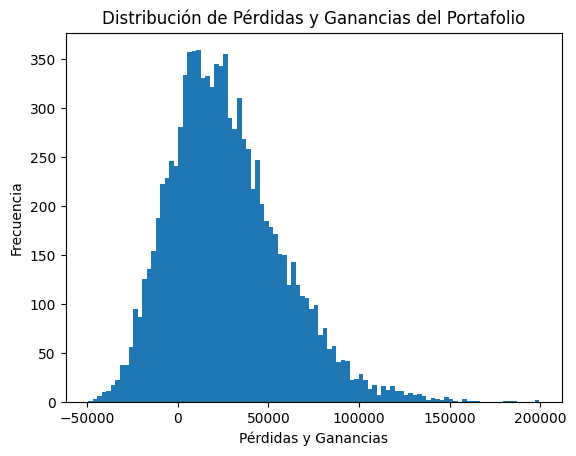

In [89]:
plt.hist(PyG_port_1, bins=100)
plt.title('Distribución de Pérdidas y Ganancias del Portafolio')
plt.xlabel('Pérdidas y Ganancias')
plt.ylabel('Frecuencia')
plt.show()

## 3. Portafolio 2
Se calcula la distribución de pérdidas y ganancias con pesos de 33 %, 33 % y 34 %, respectivamente, en el orden de las columnas de precios.

In [90]:
w_2 = np.array([0.33, 0.33, 0.34])
values = capital*w_2
acciones = np.floor(values/prices.iloc[-1].values)
valor_port = np.sum(acciones*ST, axis=1)
PyG_2 = valor_port - capital
PyG_port_2 = PyG_2

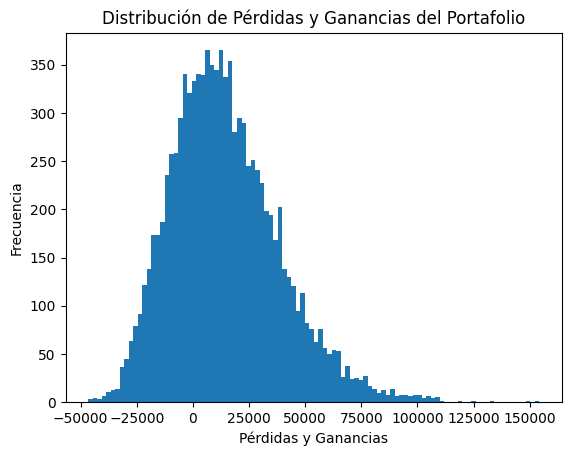

In [91]:
plt.hist(PyG_port_2, bins=100)
plt.title('Distribución de Pérdidas y Ganancias del Portafolio')
plt.xlabel('Pérdidas y Ganancias')
plt.ylabel('Frecuencia')
plt.show()

## 4. Portafolio 3
Se repite el cálculo con pesos de 20 %, 20 % y 60 %, respectivamente, en el orden de las columnas de precios.

In [92]:
w_3 = np.array([0.2, 0.2, 0.6])
values = capital*w_3
acciones = np.floor(values/prices.iloc[-1].values)
valor_port = np.sum(acciones*ST, axis=1)
PyG_3 = valor_port - capital
PyG_port_3 = PyG_3

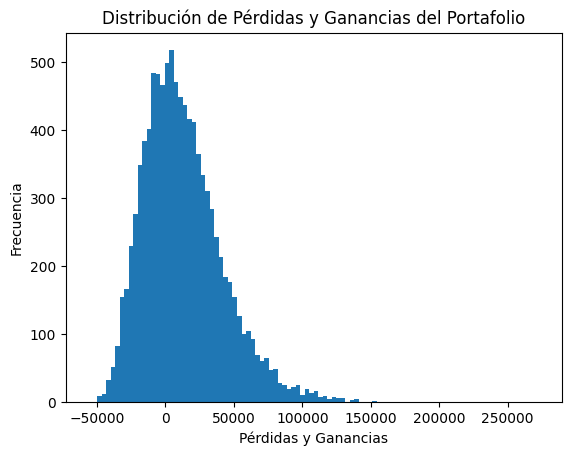

In [93]:
plt.hist(PyG_port_3, bins=100)
plt.title('Distribución de Pérdidas y Ganancias del Portafolio')
plt.xlabel('Pérdidas y Ganancias')
plt.ylabel('Frecuencia')
plt.show()

# VaR y CVaR

Las funciones muestran la distribución de pérdidas y ganancias, su media y sus cuartiles. El valor etiquetado como VaR 5 % es el percentil 5 de la PyG; el CVaR es la PyG promedio de los escenarios en esa cola inferior. Los valores negativos representan pérdidas.

In [94]:
def graf_hist(PyG_port):
    mu = PyG_port.mean()
    Q1 = np.percentile(PyG_port, 25)
    Q3 = np.percentile(PyG_port, 75)
    Q2 = np.percentile(PyG_port, 50)
    VaR_5 = np.percentile(PyG_port, 5)

    plt.hist(PyG_port, bins=100, alpha=0.7, color='skyblue')
    plt.title('Distribución de Pérdidas y Ganancias del Portafolio')
    plt.xlabel('Pérdidas y Ganancias')
    plt.ylabel('Frecuencia')
    plt.axvline(mu, color='red', linestyle='--', label=f'Media: {mu:.2f}')
    plt.axvline(Q1, color='blue', linestyle='--', label=f'Q1: {Q1:.2f}')
    plt.axvline(Q2, color='green', linestyle='--', label=f'Q2: {Q2:.2f}')
    plt.axvline(Q3, color='orange', linestyle='--', label=f'Q3: {Q3:.2f}')
    plt.axvline(VaR_5, color='purple', linestyle='--', label=f'VaR 5%: {VaR_5:.2f}')
    plt.legend()
    plt.show()

def riesgo(PyG_port):
    VaR_5 = np.percentile(PyG_port, 5)
    CVar_5 = PyG_port[PyG_port <= VaR_5].mean()
    print(f'VaR 5%: {VaR_5:.2f}')
    print(f'CVaR 5%: {CVar_5:.2f}')

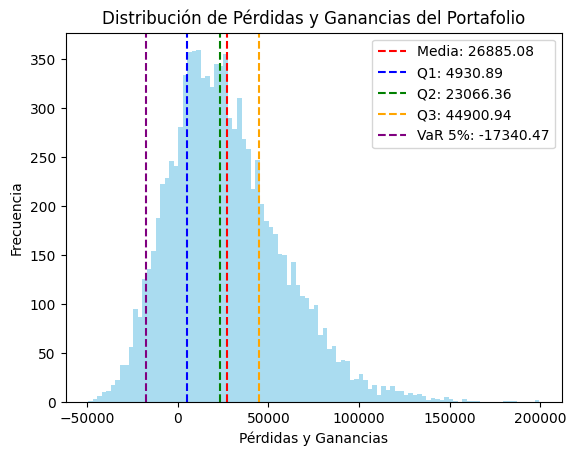

VaR 5%: -17340.47
CVaR 5%: -24990.00


In [95]:
graf_hist(PyG_port_1)
riesgo(PyG_port_1)

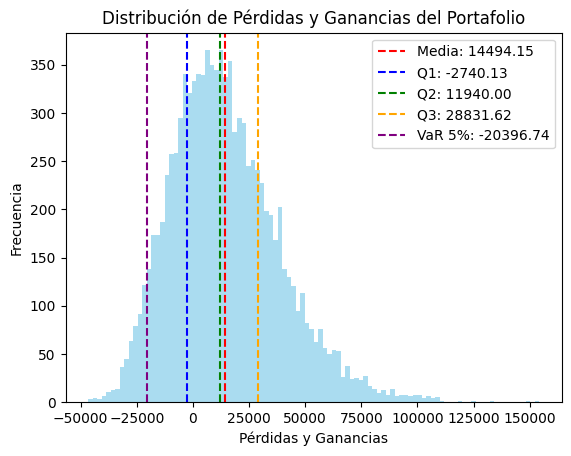

VaR 5%: -20396.74
CVaR 5%: -26391.63


In [96]:
graf_hist(PyG_port_2)
riesgo(PyG_port_2)

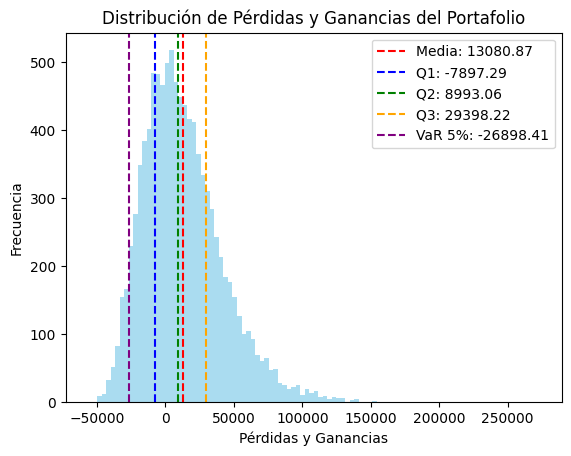

VaR 5%: -26898.41
CVaR 5%: -33170.01


In [97]:
graf_hist(PyG_port_3)
riesgo(PyG_port_3)

## Conclusión

En los resultados guardados, el portafolio 1 presenta el cuantil de PyG al 5 % menos negativo y la menor pérdida promedio en la cola; le sigue el portafolio 2 y, finalmente, el portafolio 3.

| Portafolio | VaR 5 % (cuantil de PyG) | CVaR 5 % (PyG promedio en la cola) |
|---|---:|---:|
| 1 | -17,340.47 | -24,990.00 |
| 2 | -20,396.74 | -26,391.63 |
| 3 | -26,898.41 | -33,170.01 |

Según esta simulación, el portafolio 3 presenta mayor riesgo de pérdida en escenarios adversos. Por lo tanto sería necesario tener en cuenta el rendimiento y la volatilidad del portafolio, pero en base a estas metricas el portafolio que tiene menor riesgo es el primero.